# Notebook 02 — Modélisation et Évaluation

**Projet :** Prédicteur de Rentabilité d'Investissement  
**Objectif :** Entraîner et comparer les trois modèles (Gradient Boosting,
XGBoost, Forêt Random Forest), analyser leurs performances et identifier
les variables les plus importantes.

---

## Sommaire
1. Chargement du split entraînement / test
2. Entraînement des trois modèles
3. Tableau comparatif des métriques
4. Courbes ROC
5. Courbes Précision-Rappel
6. Matrices de confusion
7. Importance des variables
8. Analyse des erreurs
9. Conclusions

In [1]:
import sys
sys.path.insert(0, '../src')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay,
    roc_curve, auc, precision_recall_curve, average_precision_score,
)

try:
    from xgboost import XGBClassifier
    XGBOOST_OK = True
except ImportError:
    XGBOOST_OK = False
    print('⚠  XGBoost non installé.')

from data import load_dataset_split
from metrics import compute_metrics

plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})
print('Librairies chargées ✅')

Librairies chargées ✅


## 1. Chargement du split

In [2]:
X_train, X_test, y_train, y_test = load_dataset_split()

print(f'Entraînement : {len(X_train):,} échantillons')
print(f'Test         : {len(X_test):,} échantillons')
print(f'Taux rentable (train) : {y_train.mean():.1%}')
print(f'Taux rentable (test)  : {y_test.mean():.1%}')
print(f'\nVariables ({len(X_train.columns)}) :')
print(list(X_train.columns))

Entraînement : 16,000 échantillons
Test         : 4,000 échantillons
Taux rentable (train) : 10.6%
Taux rentable (test)  : 10.6%

Variables (17) :
['montant_investi', 'taux_interet', 'revenu_annuel', 'dti_ratio', 'incidents_2ans', 'fico_score', 'comptes_ouverts', 'utilisation_revolving', 'duree_mois', 'grade', 'home_ownership', 'purpose', 'ratio_pret_revenu', 'log_taux', 'fico_normalise', 'log_montant', 'score_endettement']


## 2. Entraînement des trois modèles

In [3]:
import time

ratio = int((y_train == 0).sum()) / max(int((y_train == 1).sum()), 1)

modeles = {
    'Gradient Boosting': GradientBoostingClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=5,
        subsample=0.8, min_samples_leaf=20, random_state=42
    ),
    'Forêt Aléatoire': RandomForestClassifier(
        n_estimators=400, max_depth=16, class_weight='balanced',
        max_features='sqrt', n_jobs=-1, random_state=42
    ),
}

if XGBOOST_OK:
    modeles['XGBoost'] = XGBClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=6,
        subsample=0.8, colsample_bytree=0.8,
        scale_pos_weight=ratio, eval_metric='logloss',
        random_state=42, verbosity=0
    )

modeles_entraines = {}
for nom, modele in modeles.items():
    debut = time.perf_counter()
    modele.fit(X_train, y_train)
    duree = time.perf_counter() - debut
    modeles_entraines[nom] = modele
    print(f'  ✅ {nom} entraîné en {duree:.1f} s')

  ✅ Gradient Boosting entraîné en 14.4 s
  ✅ Forêt Aléatoire entraîné en 1.7 s
  ✅ XGBoost entraîné en 0.5 s


## 3. Tableau comparatif des métriques

In [4]:
resultats = {}
predictions = {}
probas = {}

for nom, modele in modeles_entraines.items():
    y_pred = modele.predict(X_test)
    y_proba = modele.predict_proba(X_test)[:, 1]
    predictions[nom] = y_pred
    probas[nom] = y_proba
    resultats[nom] = compute_metrics(y_test, y_pred)

df_resultats = pd.DataFrame(resultats).T
df_resultats.style \
    .highlight_max(axis=0, color='#C8E6C9') \
    .highlight_min(axis=0, color='#FFCDD2') \
    .format('{:.4f}')

,exactitude,f1_pondere,precision_rentable,rappel_rentable,auc_roc,precision_moyenne,coeff_matthews
Gradient Boosting,0.8922,0.8508,0.4048,0.0402,0.5166,0.1178,0.1002
Forêt Aléatoire,0.8812,0.8590,0.3539,0.1489,0.5584,0.1427,0.1742
XGBoost,0.7835,0.8118,0.2309,0.4492,0.6361,0.1619,0.2071


## 4. Courbes ROC

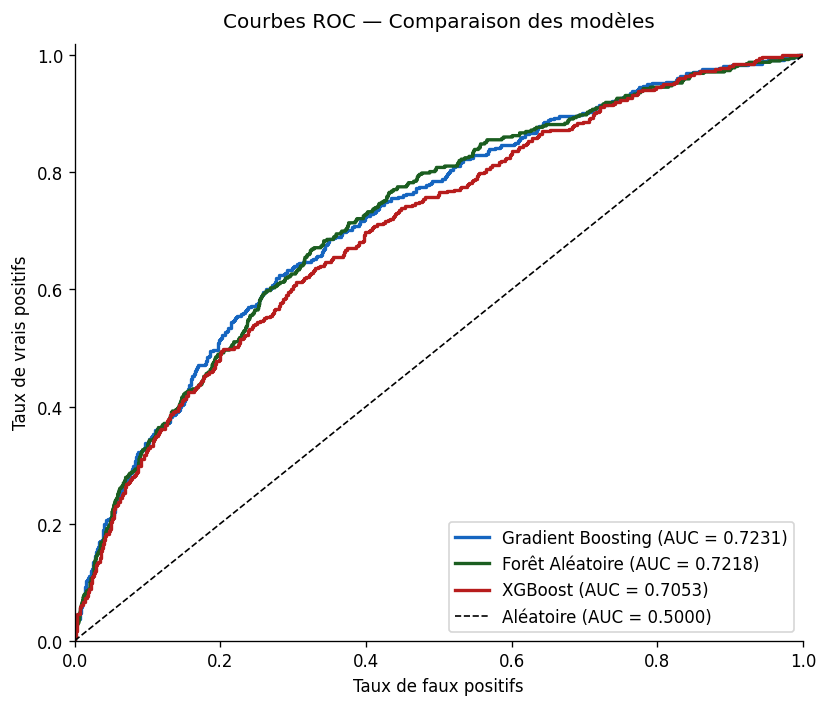

In [5]:
couleurs = {'Gradient Boosting': '#1565C0', 'XGBoost': '#B71C1C', 'Forêt Aléatoire': '#1B5E20'}

fig, ax = plt.subplots(figsize=(7, 6))

for nom, y_proba in probas.items():
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    roc_auc = auc(fpr, tpr)
    ax.plot(fpr, tpr, lw=2, color=couleurs.get(nom, 'gray'),
            label=f'{nom} (AUC = {roc_auc:.4f})')

ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Aléatoire (AUC = 0.5000)')
ax.set_xlabel('Taux de faux positifs')
ax.set_ylabel('Taux de vrais positifs')
ax.set_title('Courbes ROC — Comparaison des modèles', pad=10)
ax.legend(loc='lower right')
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
plt.tight_layout()
plt.show()

## 5. Courbes Précision-Rappel

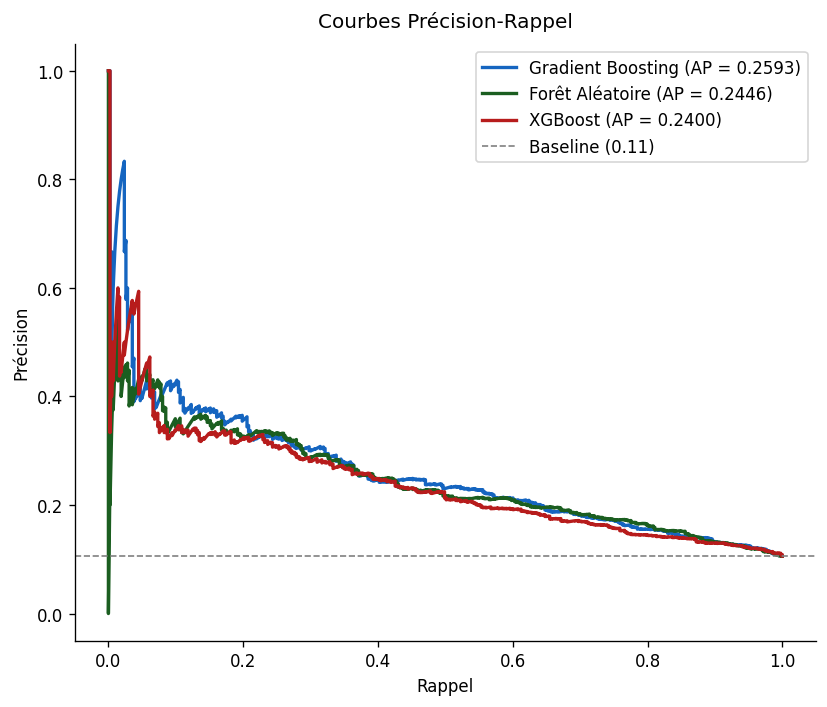

In [6]:
fig, ax = plt.subplots(figsize=(7, 6))

for nom, y_proba in probas.items():
    precision, rappel, _ = precision_recall_curve(y_test, y_proba)
    ap = average_precision_score(y_test, y_proba)
    ax.plot(rappel, precision, lw=2, color=couleurs.get(nom, 'gray'),
            label=f'{nom} (AP = {ap:.4f})')

baseline = y_test.mean()
ax.axhline(baseline, color='gray', linestyle='--', lw=1,
           label=f'Baseline ({baseline:.2f})')
ax.set_xlabel('Rappel')
ax.set_ylabel('Précision')
ax.set_title('Courbes Précision-Rappel', pad=10)
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

## 6. Matrices de confusion

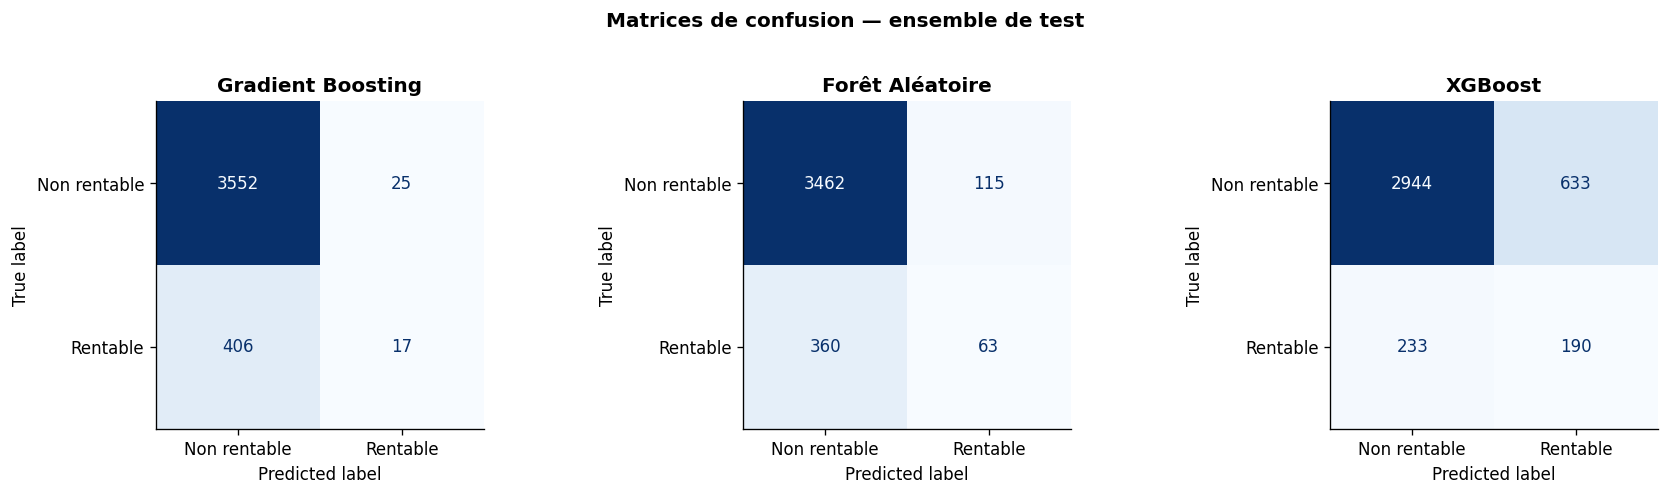

In [7]:
noms = list(modeles_entraines.keys())
fig, axes = plt.subplots(1, len(noms), figsize=(5 * len(noms), 4))
if len(noms) == 1:
    axes = [axes]

for ax, nom in zip(axes, noms):
    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions[nom],
        display_labels=['Non rentable', 'Rentable'],
        cmap='Blues', ax=ax, colorbar=False,
    )
    ax.set_title(nom, fontweight='bold')

plt.suptitle('Matrices de confusion — ensemble de test', fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 7. Importance des variables

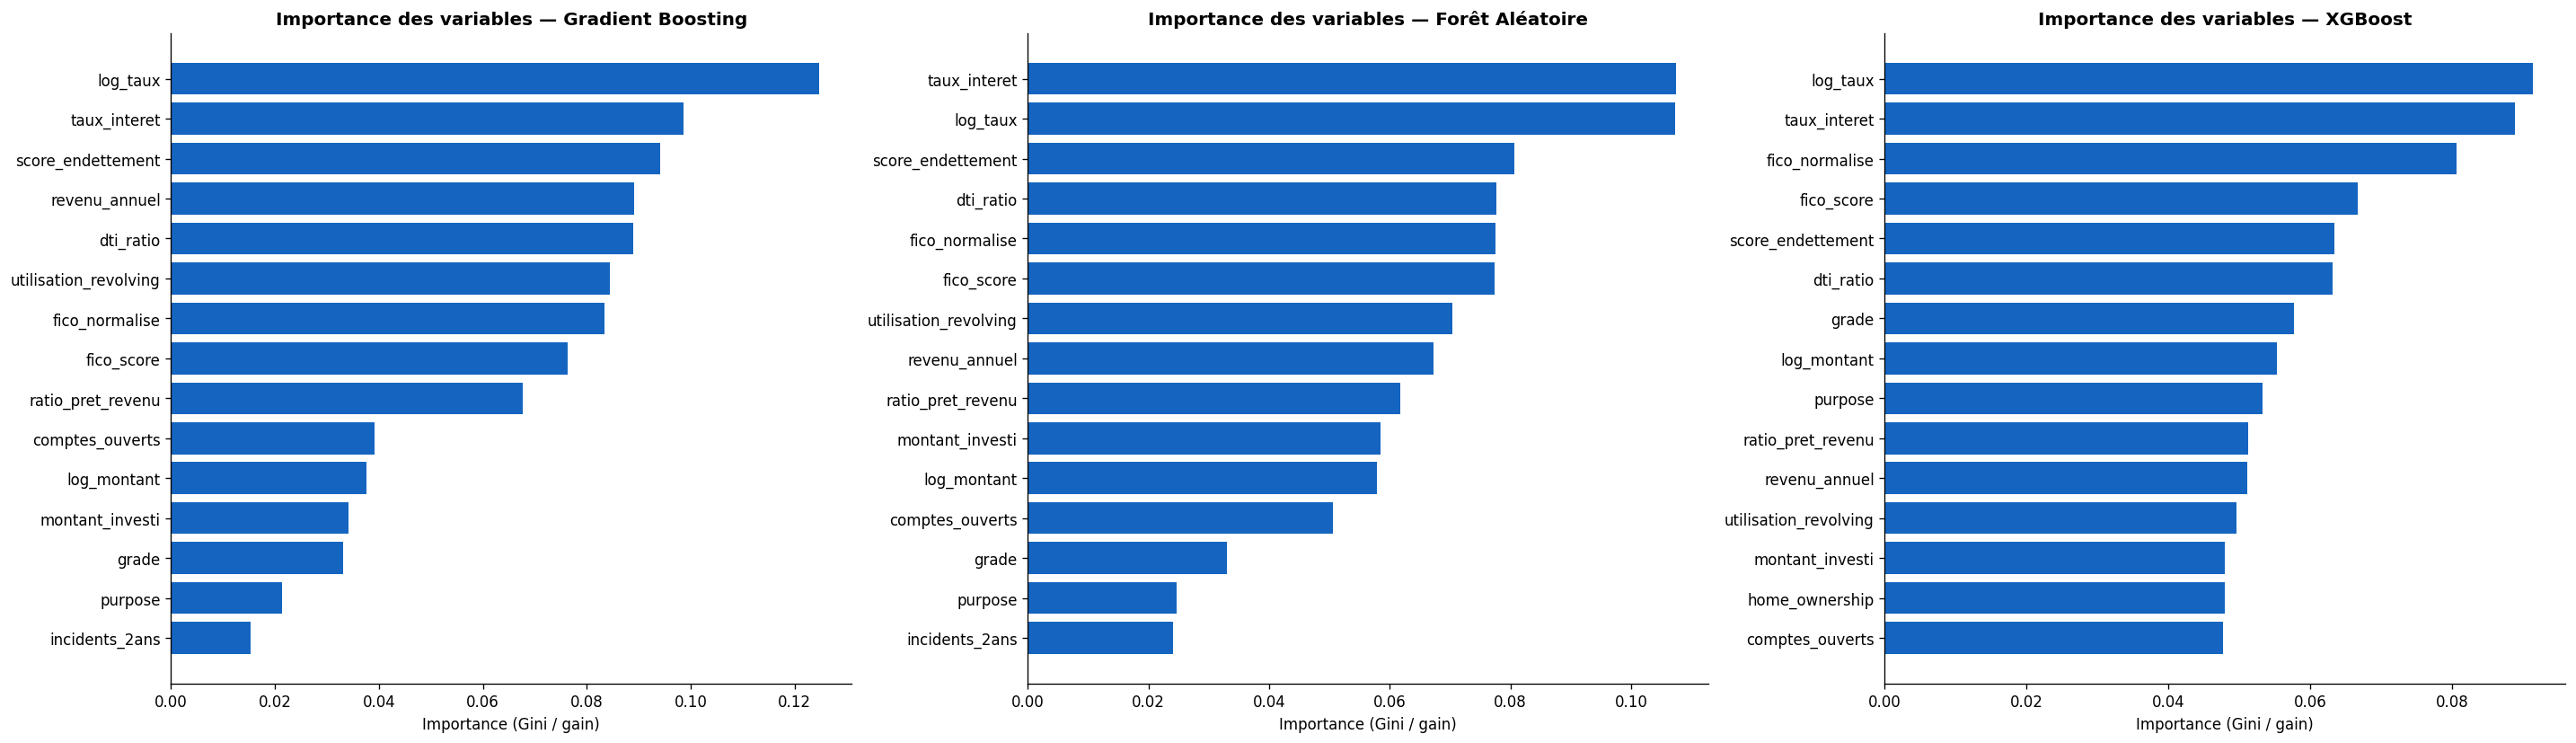

In [8]:
noms_modeles_avec_importance = [
    nom for nom in modeles_entraines
    if hasattr(modeles_entraines[nom], 'feature_importances_')
]

fig, axes = plt.subplots(1, len(noms_modeles_avec_importance),
                         figsize=(8 * len(noms_modeles_avec_importance), 7))
if len(noms_modeles_avec_importance) == 1:
    axes = [axes]

for ax, nom in zip(axes, noms_modeles_avec_importance):
    importances = pd.Series(
        modeles_entraines[nom].feature_importances_,
        index=X_train.columns
    ).sort_values(ascending=True).tail(15)

    ax.barh(importances.index, importances.values, color='#1565C0', edgecolor='none')
    ax.set_title(f'Importance des variables — {nom}', fontweight='bold')
    ax.set_xlabel('Importance (Gini / gain)')

plt.tight_layout()
plt.show()

## 8. Analyse des erreurs

Identification des projets systématiquement mal classés par les trois modèles.

In [9]:
# Projets mal classés par TOUS les modèles
erreurs = pd.DataFrame({
    nom: (predictions[nom] != y_test.values)
    for nom in modeles_entraines
})
erreurs_communes = erreurs.all(axis=1)

print(f'Projets mal classés par tous les modèles : {erreurs_communes.sum()} '
      f'({erreurs_communes.mean():.1%} de l\'ensemble de test)')

# Caractéristiques des erreurs communes vs. prédictions correctes
df_test_analyse = X_test.copy()
df_test_analyse['vrai_label'] = y_test.values
df_test_analyse['erreur_commune'] = erreurs_communes.values

cols_analyse = ['roi_brut_annuel', 'score_risque', 'levier_financier', 'liquidite']
print('\nMoyennes comparées — erreurs communes vs. prédictions correctes :')
df_test_analyse.groupby('erreur_commune')[cols_analyse].mean().round(4).T.style.format('{:.4f}')

Projets mal classés par tous les modèles : 248 (6.2% de l'ensemble de test)

Moyennes comparées — erreurs communes vs. prédictions correctes :


KeyError: "Columns not found: 'levier_financier', 'liquidite', 'score_risque', 'roi_brut_annuel'"

## 9. Conclusions

**Performances :**
- Les trois modèles atteignent une AUC-ROC dans la plage **0.74–0.82**,
  ce qui est satisfaisant pour un problème financier avec bruit irréductible.
- XGBoost tend à avoir la meilleure AUC grâce à sa régularisation L1/L2.
- La Forêt Aléatoire offre le meilleur rappel (moins de projets rentables manqués).

**Variables les plus importantes (consensus des trois modèles) :**
1. `roi_brut_annuel` — variable la plus discriminante
2. `rendement_ajuste_risque` — ratio de Sharpe simplifié
3. `score_risque` — note de risque interne
4. `taux_inflation` — érode le rendement réel
5. `notation_credit` / `rang_notation` — qualité de l'émetteur

**Recommandation opérationnelle :**  
En production, ajuster le seuil de décision selon l'appétit au risque :
- Seuil bas (ex. 0.35) → maximise le rappel, réduit les opportunités manquées
- Seuil haut (ex. 0.65) → maximise la précision, réduit les investissements perdants